# 05 · Evaluate before you optimise

You now have a working RAG chain. The next notebooks try to improve it: smarter retrievers,
hybrid search, reranking, tuning. **But "better" means nothing without a measurement.** Change
a prompt, try three questions, and it *feels* better. Then it fails on the fourth.

**In this notebook you will:**
- meet the evaluation set: 40 questions with reference answers and *evidence* strings,
- compute retrieval metrics by hand (hit rate, MRR), no LLM needed,
- judge answers with a cheap LLM judge,
- run **RAGAS** (faithfulness, answer relevancy, context precision, context recall),
- record a **baseline** that every later notebook is compared against,
- tell *retrieval* failures apart from *generation* failures.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: the baseline index from notebook 04, and the baseline chain
from raglab import chains
from raglab.bootstrap import ensure_index

store = ensure_index("nb04_baseline")
retriever = store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
chain = chains.build_rag_chain_with_sources(retriever)

[nb04_baseline] reusing index (109 chunks)


In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

## 1. The loop we're starting

Run the system on a fixed set of questions, measure, find out *why* things fail, change one thing,
and measure again. Notebooks 06–08 are iterations of this loop.

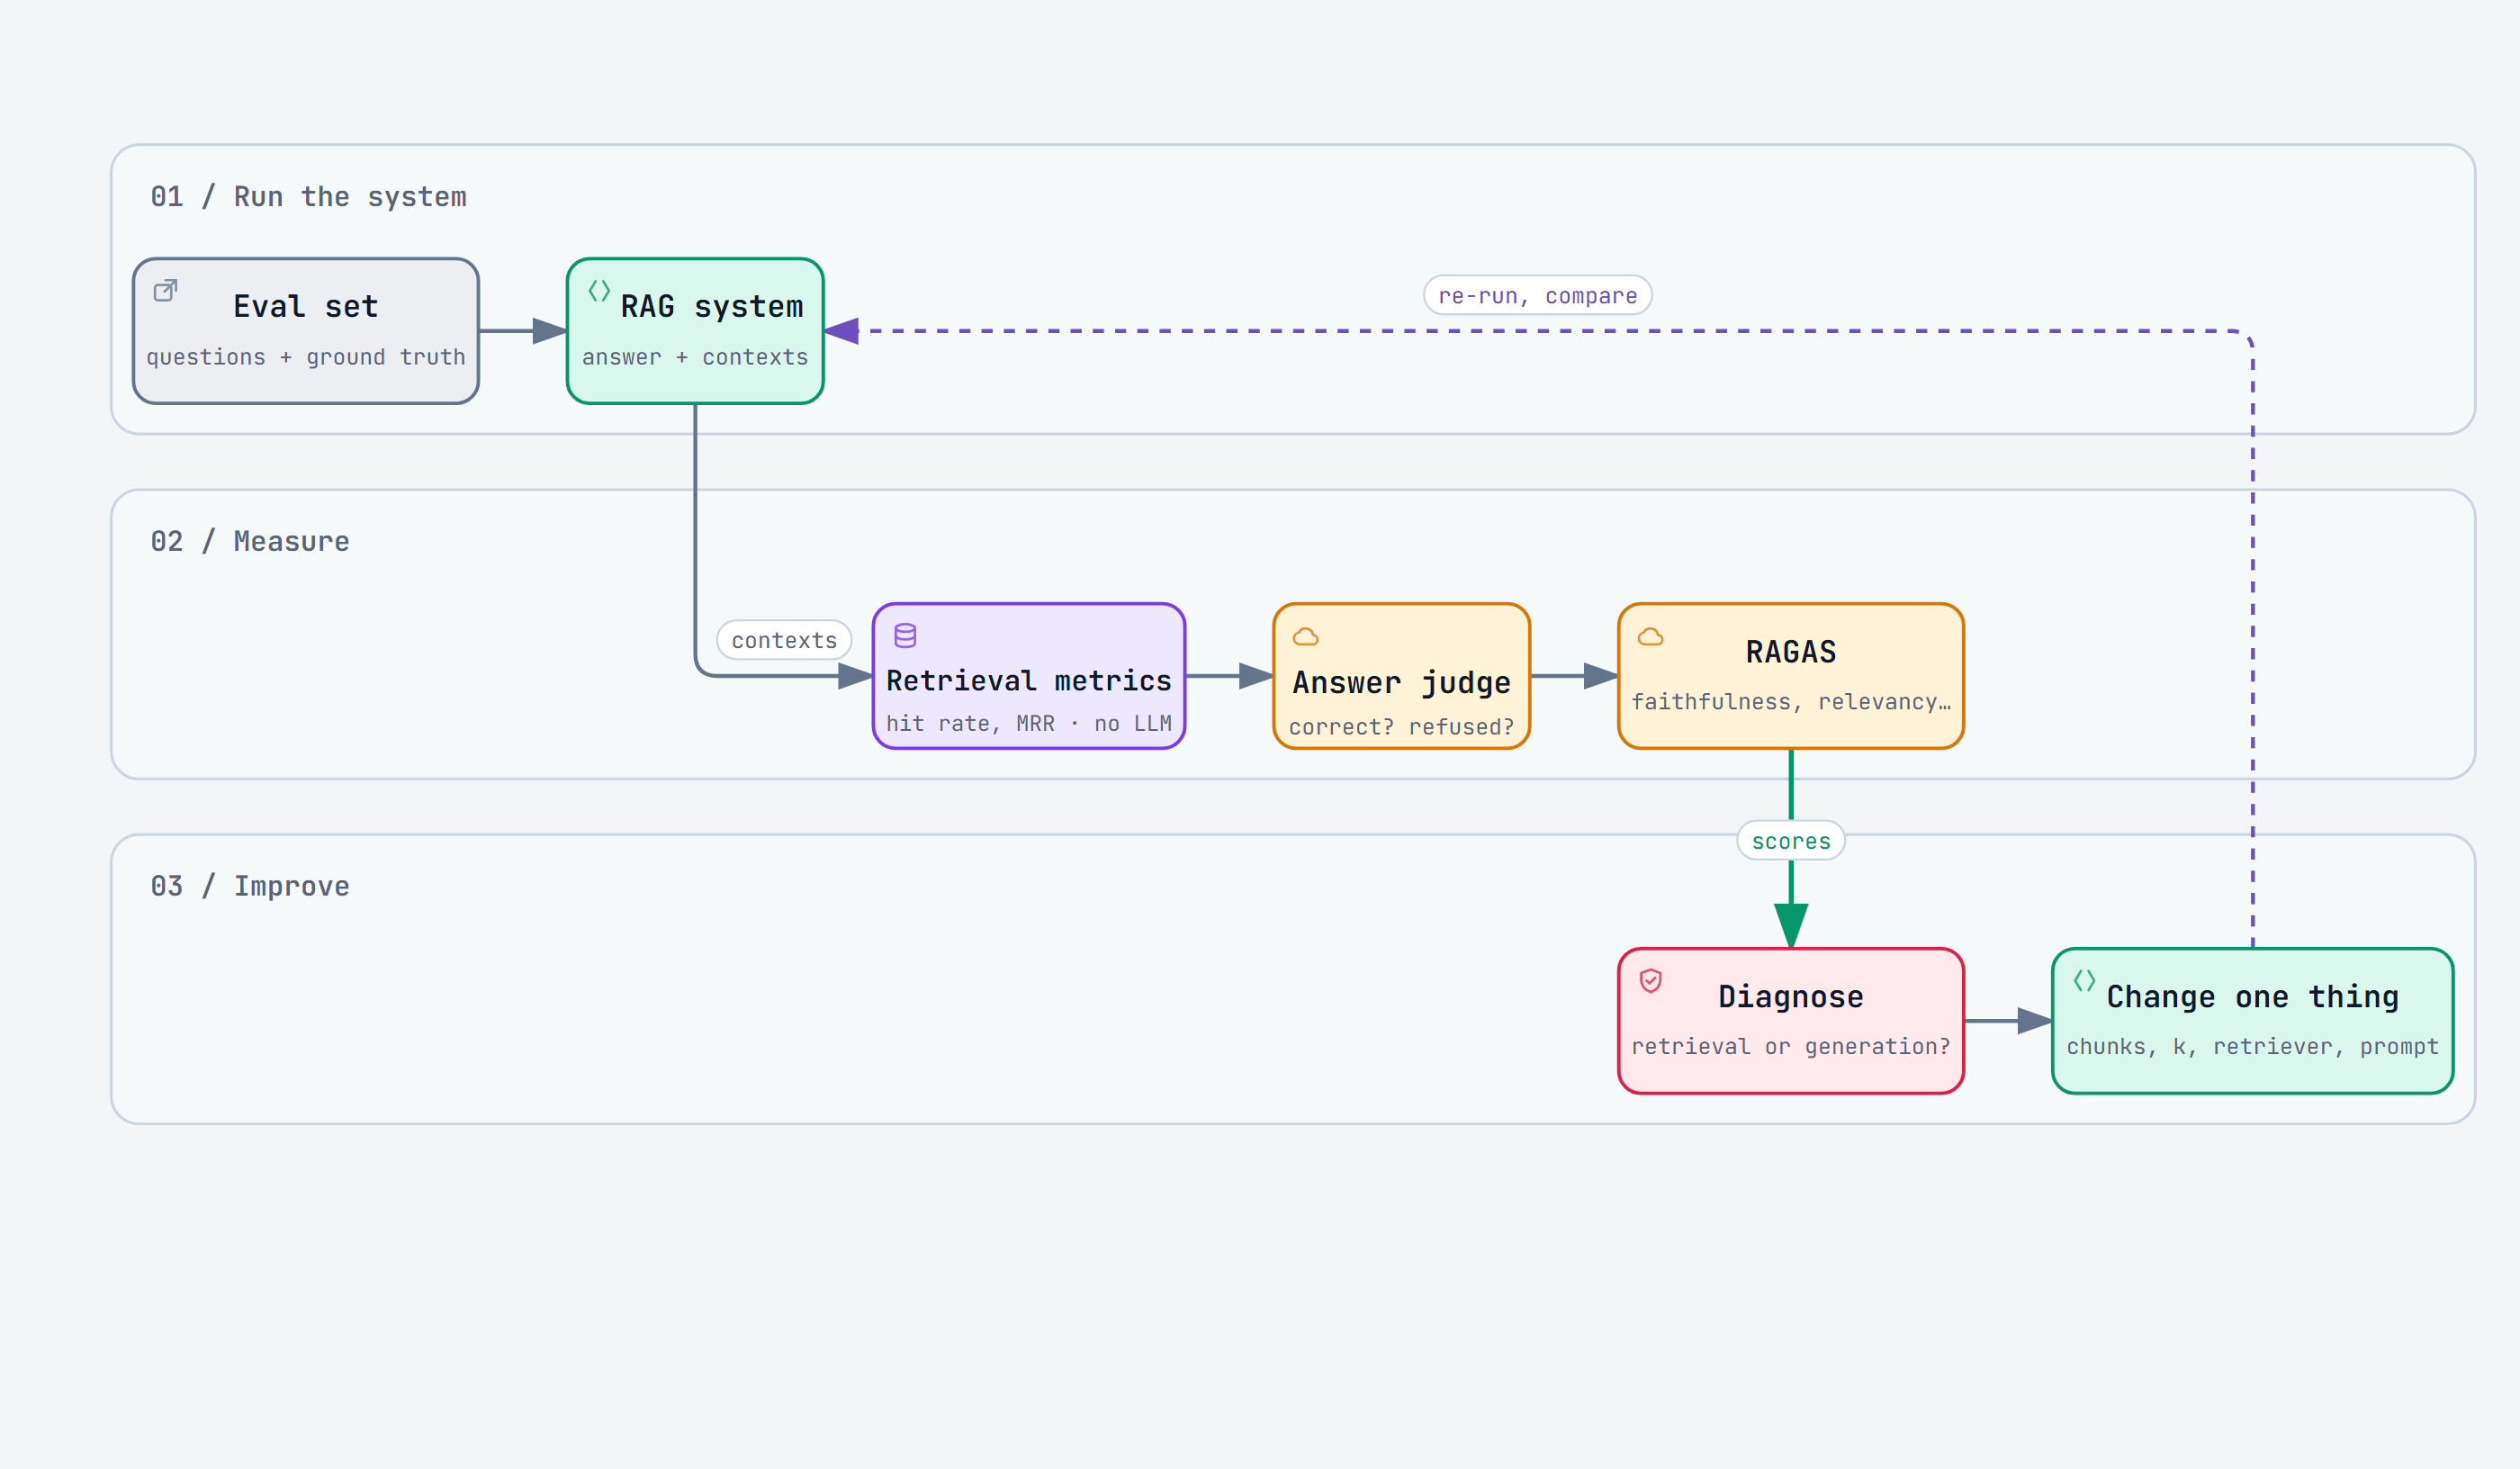

[Open interactive version](../diagrams/eval_loop.html)

In [4]:
from raglab.display import show_diagram

show_diagram("eval_loop")

## 2. The evaluation set

`data/eval/questions.json` has 40 questions about the Token Hotels documents. Each one has:

- a `category`: factual, comparative, multi-hop, metadata filter, unanswerable, conflicting
  versions, and no-search-needed (for the agent in notebook 12),
- a reference answer (`ground_truth`),
- **evidence**: short exact phrases from the source documents that prove the right chunk was found.

Evidence strings are what let us measure retrieval *without* an LLM. A build script
(`data/_build/check_eval.py`) verifies that every evidence string really appears in its source document.

In [5]:
import pandas as pd

from raglab import evaluation as ev

all_items = ev.load_eval("full", categories=None)
print(f"{len(all_items)} questions used for RAG evaluation (no_search_needed items are for notebook 12)")
pd.Series([i["category"] for i in all_items]).value_counts()

35 questions used for RAG evaluation (no_search_needed items are for notebook 12)


factual                 10
multi_hop                6
comparative              5
metadata_filter          5
unanswerable             5
conflicting_versions     4
Name: count, dtype: int64

In [6]:
pd.DataFrame(all_items)[["id", "category", "question", "evidence"]].head(8)

,id,category,question,evidence
0,1,factual,What time is check-in at Token Kyoto?,[Check-in at Token Kyoto starts at 4:00 PM]
1,2,factual,How many rooms does Token Singapore have?,[The hotel has 340 rooms]
2,3,factual,Who is the chef at Hanare?,[Chef Kenji Morimoto]
3,4,factual,How much is the tasting menu at Dar Zitoun?,[At Dar Zitoun the tasting menu costs $85]
4,5,factual,Is Wi-Fi free at Token hotels?,[Wi-Fi is free for every guest]
5,6,factual,How much is the airport transfer from Changi t...,[limousine transfer from Changi Airport costs ...
6,7,factual,What are the opening hours of Ridgeline at Tok...,"[Ridgeline — Token Queenstown, 6:00 PM - 10:00..."
7,8,factual,How many Token Circle points do I need for a f...,"[10,000 points can be exchanged]"


## 3. Retrieval metrics, by hand

For each question we retrieve k=4 chunks and check them against the evidence:

- **evidence recall**: what fraction of the evidence strings appear somewhere in the 4 chunks?
- **hit**: did we find *all* of them? The average over questions is the **hit rate**.
- **reciprocal rank (RR)**: 1 / position of the first chunk containing evidence (1st → 1.0,
  2nd → 0.5, not found → 0). The average is **MRR**: it rewards finding things *early*.

Let's do one comparative question by hand:

In [7]:
item = next(i for i in all_items if i["id"] == 13)
print("Q:", item["question"])
print("evidence:", item["evidence"])
for rank, doc in enumerate(retriever.invoke(item["question"]), start=1):
    text = ev.normalise(doc.page_content)
    found = [e for e in item["evidence"] if ev.normalise(e) in text]
    print(f"  rank {rank}: {doc.metadata['source_file']:<20} evidence found: {found}")

Q: Which has more rooms, Token Kyoto or Token Reykjavík?
evidence: ['The hotel has 64 rooms', 'The hotel has 76 rooms']
  rank 1: room_rates.csv       evidence found: []
  rank 2: hotel_profiles.pdf   evidence found: ['The hotel has 76 rooms']
  rank 3: hotel_profiles.pdf   evidence found: []
  rank 4: room_rates.csv       evidence found: []


A comparative question needs facts about *two* hotels. If only one shows up in the top 4, the
model can't compare them, however good the prompt is.

`ev.retrieval_metrics` does this for every question. It only costs embeddings for the questions,
so we always run it on the full set:

In [8]:
baseline_retrieval = ev.run_or_load(
    "nb05_baseline_retrieval",
    lambda: ev.retrieval_metrics(retriever, all_items),
    meta={"profile": "nb04_baseline", "retriever": "similarity", "k": 4},
)
ev.summarize(baseline_retrieval)

evidence_recall    0.806
hit                0.667
rr                 0.736
n_docs             4.000
latency_ms         3.500
dtype: float64

Overall numbers hide the pattern. Break them down by category:

In [9]:
baseline_retrieval.groupby("category")[["evidence_recall", "hit", "rr"]].mean().round(2)

,evidence_recall,hit,rr
category,,,
comparative,0.60,0.20,0.62
conflicting_versions,1.00,1.00,0.58
factual,0.90,0.90,0.83
metadata_filter,0.63,0.40,0.60
multi_hop,0.83,0.67,0.89


## 4. Judging the answers

Retrieval is half the story. To grade the *answers*, we compare each one with the reference
answer using a cheap LLM judge (`ev.judge_correct`). One rule is stricter: for **unanswerable**
questions, the only correct answer is the exact refusal sentence from notebook 04.

We run the chain on the 5-question **quick** subset live (about a cent):

In [10]:
quick_items = ev.load_eval("quick")
rows = ev.run_rag(chain, quick_items)
quick_answers = ev.score_answers(rows)
pd.set_option("display.max_colwidth", 120)
quick_answers

,id,category,correct,answer
0,1,factual,True,Check-in at Token Kyoto starts at 4:00 PM.
1,16,multi_hop,True,Dar Zitoun opens for dinner at 7:30 PM.
2,22,metadata_filter,False,Token Singapore has a swimming pool.
3,27,unanswerable,True,I couldn't find that in the Token Hotels documents.
4,32,conflicting_versions,True,"For a Flexible rate, you can cancel for free up to 72 hours before arrival."


## 5. RAGAS

[RAGAS](https://docs.ragas.io) is an evaluation library with LLM-judged metrics. Each one
isolates a different failure:

| Metric | Question it answers | Low score means |
|---|---|---|
| **faithfulness** | Is every claim in the answer supported by the retrieved chunks? | hallucination |
| **answer relevancy** | Does the answer address the question? | evasive or off-topic answer |
| **context precision** | Are the relevant chunks ranked near the top? | noisy retrieval |
| **context recall** | Do the chunks contain everything the reference answer needs? | missing information |

RAGAS makes several LLM calls per question and metric, so always check the cost first.
(Unanswerable questions are skipped: these metrics assume there is a real answer.)

In [11]:
from raglab import llm

estimate = ev.estimate_ragas_cost(len(rows))
quick_ragas = ev.ragas_scores(rows) if llm.check_budget(estimate) else None
quick_ragas

Estimated cost: $0.0078 (limit $0.05) → OK


,id,category,faithfulness,answer_relevancy,context_precision,context_recall
0,1,factual,1.0,0.976,1.000,1.0
1,16,multi_hop,1.0,0.608,1.000,1.0
2,22,metadata_filter,1.0,0.606,0.000,0.0
3,32,conflicting_versions,1.0,0.797,0.917,0.0


Read each row against the answers above. A correct answer can still score low on
`context_recall`: that happens when the *reference* answer mentions something the chunks didn't
contain (for example, the reference for the cancellation question also mentions the old 48-hour
policy). Metrics are tools for finding things to look at, not verdicts.

## 6. The baseline at full size

Five questions are too few to compare systems: one lucky answer moves the score by 20 points.
The full-size baseline covers all 35 RAG questions. It costs a few cents, so the notebook
shows the **saved** results from the series' full run (`results/`). Set `RAGLAB_FULL_RUN=1` to
recompute and overwrite them yourself.

In [12]:
settings = get_settings()


def full_answers():
    if not settings.full_run:
        return quick_answers  # no saved run and no full run requested: fall back to the live quick results
    return ev.score_answers(ev.run_rag(chain, all_items))


baseline_answers = ev.run_or_load(
    "nb05_baseline_answers", full_answers, meta={"profile": "nb04_baseline", "retriever": "similarity", "k": 4}
)
print(f"accuracy: {baseline_answers['correct'].mean():.0%} of {len(baseline_answers)} questions")
baseline_answers.groupby("category")["correct"].mean().round(2)

accuracy: 80% of 5 questions


category
conflicting_versions    1.0
factual                 1.0
metadata_filter         0.0
multi_hop               1.0
unanswerable            1.0
Name: correct, dtype: float64

In [13]:
def full_ragas():
    if not settings.full_run:
        return quick_ragas if quick_ragas is not None else pd.DataFrame()
    return ev.ragas_scores(ev.run_rag(chain, all_items))


baseline_ragas = ev.run_or_load(
    "nb05_baseline_ragas", full_ragas, meta={"profile": "nb04_baseline", "retriever": "similarity", "k": 4}
)
ev.summarize(baseline_ragas)

faithfulness         1.000
answer_relevancy     0.747
context_precision    0.729
context_recall       0.500
dtype: float64

## 7. Retrieval failure or generation failure?

For every wrong answer, ask one question first: **was the evidence retrieved?**

- **No** → a *retrieval* failure. No prompt can fix it; change chunking, k or the retriever.
- **Yes** → a *generation* failure. The facts were there and the model missed or misused them;
  change the prompt or the model.

In [14]:
joined = baseline_answers.merge(baseline_retrieval[["id", "hit", "evidence_recall"]], on="id", how="left")
wrong = joined[~joined["correct"]].copy()
wrong["failure"] = wrong["hit"].map({True: "generation", False: "retrieval"}).fillna("n/a (no evidence)")
wrong[["id", "category", "failure", "evidence_recall", "answer"]]

,id,category,failure,evidence_recall,answer
2,22,metadata_filter,retrieval,0.5,Token Singapore has a swimming pool.


Keep this table in mind. Most failures of this baseline are **retrieval** failures, concentrated
in comparative and metadata-filter questions: questions that need facts from several chunks, or
a filter on hotel attributes. That's exactly what notebooks 06 and 07 go after. Notebook 08 turns
this triage into a reusable tool.

## Your turn

1. Change the baseline to `k=8` and recompute `ev.retrieval_metrics` (embeddings only, so about
   free). Which categories improve? What might a bigger k cost on the *generation* side?
2. Write three new evaluation questions about the corpus with their evidence strings, and run
   `ev.retrieval_metrics` on them. (Run `data/_build/check_eval.py`'s logic in your head: is your
   evidence really in the document, word for word?)
3. Find a question where the judge's verdict seems wrong to you. What would make the judge stricter or fairer?

## Key takeaways

- Build an evaluation set before optimising, and include hard categories (multi-hop, unanswerable, conflicting).
- Retrieval metrics with evidence strings are cheap and need no LLM. Run them on everything.
- LLM-judged metrics (the judge, RAGAS) cost money: estimate first, use a quick subset while iterating.
- Always split failures into retrieval vs generation before deciding what to change.

**Added to raglab:** `evaluation.load_eval / retrieval_metrics / summarize / run_rag / judge_correct /
score_answers / ragas_scores / estimate_ragas_cost / save_run / load_run / run_or_load / compare_runs / compare`.

In [15]:
cost.report()

model                       calls   in tokens  out tokens       USD
gpt-6-luna                     49      44,630       2,353    0.0056
text-embedding-3-small          8         167           0    0.0000
total                          57                            0.0056
